Tested with:
- Python 3.13.9
- numpy 2.4.4
- pandas 2.3.3
- scikit-learn 1.7.2
- rdkit 2026.3.1
- ase 3.26.0
- torch 2.12.0+cu126
- torch_geometric 2.8.0
- scikit-activeml 1.0.0
- skorch 1.3.1

In [1]:
import warnings
warnings.filterwarnings('ignore')

import pprint  # Pretty print data structures
import numpy as np
import pandas as pd
import math
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
import joblib
import skactiveml
import matplotlib.ticker as ticker
from pymatgen.core import Composition
from matminer.featurizers.composition import ElementProperty, ElementFraction
from matminer.featurizers.base import MultipleFeaturizer
from joblib import Parallel, delayed
from sklearn.model_selection import train_test_split
from sklearn import metrics
from sklearn.metrics import r2_score, root_mean_squared_error, mean_absolute_error, mean_squared_error
from sklearn.model_selection import KFold, cross_val_score, cross_validate
from sklearn.model_selection import learning_curve
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.base import clone
from mpl_toolkits.axes_grid1 import make_axes_locatable
from sklearn.ensemble import BaggingRegressor, RandomForestRegressor, VotingRegressor
from sklearn.kernel_ridge import KernelRidge
from sklearn.kernel_approximation import Nystroem # Approximate a kernel map using a subset of the training data, KRR on QM9 is computationally infeasible
from sklearn.linear_model import Ridge
from xgboost import XGBRegressor
from skactiveml.regressor import SklearnRegressor
from skactiveml.pool import RandomSampling, QueryByCommittee, TypiClust
from skactiveml.utils import MISSING_LABEL, labeled_indices, unlabeled_indices, call_func
plt.style.use('ggplot')  # Set Matplotlib style to 'ggplot'

# Config

BLACKLIST_COLS = ['e_form','formula', 'composition', 'Unnamed: 0']
TARGET_COL = 'e_form'
Magpie_features = ElementProperty.from_preset('magpie').feature_labels()
innate_features = [
    'composition',
    'e_form',
]
features_full = innate_features + Magpie_features
features = [c for c in features_full if c not in BLACKLIST_COLS]

def build_X(df, scaler=StandardScaler(), train=False, raw=False):
    '''
    Build X with scaled continuous part and fingerprints.

    Args:
        df: dataframe with a 'smiles' column and qm9_features columns
        scaler: fitted scaler, or None to create a StandardScaler
        train: if True, fit scaler on continuous features
        raw: if True, return unscaled X
        n_jobs: number of CPU cores to use for fingerprinting

    Returns:
        X: feature matrix
    '''
    df = df.copy()
    X = df[features].to_numpy()

    if raw:
        return X

    X = (
        scaler.fit_transform(X) if train
        else scaler.transform(X)
    )

    return X

def plot_prediction(X, y_true, model, model_name=None, name=TARGET_COL, figsize=(6, 6), save=None, format='pdf'):
    '''
    Plot predictions for the given model and data.

    Args:
        X : Input features (np.array).
        y_true : True target values (np.array).
        model: Fitted model.
        model_name: Name of the model (str).
        name: Name of the target value (str).
        figsize: Figure size (tuple).
        save: Save path (str).
        format: Save format (str).
    '''
    y_pred = model.predict(X)
    errors = np.abs(y_true - y_pred)
    fig, ax = plt.subplots(figsize=figsize)
    
    sc = ax.scatter(y_true, y_pred, c=errors, cmap='viridis', label='predicted values')
    ax.plot(y_true, y_true, 'r-', label='true values')
    
    ax.set_xlabel(f'True Value (eV/atom)', fontsize=14)
    ax.set_ylabel(f'Predicted Value (eV/atom)', fontsize=14)
    ax.legend(facecolor='white', fontsize=12)
    ax.set_aspect('equal', adjustable='box')
    # if model_name is None:
    #     ax.set_title(f'{model.__class__.__name__} prediction plot\n{name}', fontsize=16)
    # else:
    #     ax.set_title(f'{model_name} prediction plot\n{name}', fontsize=16)

    divider = make_axes_locatable(ax)
    cax = divider.append_axes('right', size='5%', pad=0.15)
    cbar = fig.colorbar(sc, cax=cax)
    cbar.set_label('Absolute Error (eV/atom)', fontsize=14)
    cbar.ax.yaxis.set_major_formatter(ticker.FormatStrFormatter('%.1f'))

    plt.tight_layout()
    
    if save is not None:
        fig.savefig(save, format=format, dpi=300)
    plt.show()
    print('Training scores:')
    print(f'MAE = {mean_absolute_error(y_true,y_pred):.4f}')
    print(f'MSE = {mean_squared_error(y_true,y_pred):.4f}')
    print(f'RMSE = {root_mean_squared_error(y_true,y_pred):.4f}')
    print(f'r^2 = {r2_score(y_true,y_pred):.4f}')

### Load dataset

In [ ]:
from matminer.datasets import load_dataset
df = load_dataset('matbench_mp_e_form')

# Stratified split
df = pd.read_csv('../data/matbench/e_form/matbench_composition.csv')

df['composition'] = df['composition'].apply(Composition)

# Define element featurizers
featurizer = ElementProperty.from_preset('magpie')

# Featurize
featurizer.set_n_jobs(1)
df = featurizer.featurize_dataframe(df, col_id='composition', ignore_errors=True)

# 1. Split 80% train, 20% temp
strat_bins = pd.qcut(df['e_form'], q=20, labels=False)
df_train, df_temp = train_test_split(df, test_size=0.2, stratify=strat_bins, random_state=42)

# 2. Split temp 50/50 to get 10% test, 10% val
temp_bins = pd.qcut(df_temp['e_form'], q=20, labels=False)
df_test, df_val = train_test_split(df_temp, test_size=0.5, random_state=42, stratify=temp_bins)

# 3. Save to disk
df_train.to_csv('../data/matbench/e_form/matbench_train.csv', index=False)
df_test.to_csv('../data/matbench/e_form/matbench_test.csv', index=False)
df_val.to_csv('../data/matbench/e_form/matbench_val.csv', index=False)

In [2]:
TARGET_COL = 'e_form'
# Load
df_train = pd.read_csv('../data/matbench/e_form/matbench_train.csv')
df_test = pd.read_csv('../data/matbench/e_form/matbench_test.csv')
df_val = pd.read_csv('../data/matbench/e_form/matbench_val.csv')

X_train = build_X(df_train, train=True)
X_test = build_X(df_test)
X_val = build_X(df_val)

y_train = df_train[TARGET_COL].values
y_test = df_test[TARGET_COL].values
y_val = df_val[TARGET_COL].values

print(f'Train set Molecules: {X_train.shape[0]}  |  Features: {X_train.shape[1]}')
print(f'Test set Molecules: {X_test.shape[0]}  |  Features: {X_test.shape[1]}')
print(f'Validate set Molecules: {X_val.shape[0]}  |  Features: {X_val.shape[1]}')

Train set Molecules: 106201  |  Features: 132
Test set Molecules: 13275  |  Features: 132
Validate set Molecules: 13276  |  Features: 132


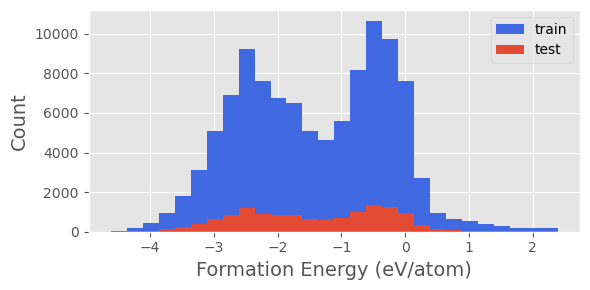

2.4995497873022234
-4.612092007715515


In [5]:
plt.figure(figsize=(6, 3))
bin_width = 0.25
bin_train = np.arange(min(df_train[TARGET_COL]), max(df_train[TARGET_COL]), bin_width)
plt.hist(df_train[TARGET_COL], bins=bin_train, color='royalblue', label='train')
plt.hist(df_test[TARGET_COL], bins=bin_train, label='test')
plt.xlabel('Formation Energy (eV/atom)', fontsize=14)
plt.ylabel('Count', fontsize=14)
plt.legend()
plt.tight_layout()
plt.savefig('../data/matbench/e_form/matbench_train_test_distribution.pdf', format='pdf', dpi=300,)
plt.show()
print(max(df_train[TARGET_COL]))
print(min(df_train[TARGET_COL]))

# Baseline

### Training

In [ ]:
rf = RandomForestRegressor(
    n_estimators=500,
    max_depth=None, 
    min_samples_split=2, 
    min_samples_leaf=1,
    max_features=0.8,
    n_jobs=-1,
    random_state=42
)

kr = Pipeline([
    ('nystroem', Nystroem(
        kernel='laplacian', 
        n_components=2500,
        gamma=0.01,          # This is the most important hyperparameter to tune
        n_jobs=-1,
        random_state=42,
    )),
    ('ridge', Ridge(alpha=0.01))
])

xgb = XGBRegressor(
    booster='gbtree',
    colsample_bytree=0.8,
    learning_rate=0.1,
    max_depth=4,
    min_child_weight=3,
    n_estimators=500,
    reg_alpha=1.0,
    reg_lambda=1.0,
    subsample=0.6,
)

com = VotingRegressor(
    estimators=[
        ('rf', clone(rf)),
        ('xgb', clone(xgb)),
        ('kr', clone(kr)),
    ],
    n_jobs=-1,
)

com.fit(X_train,y_train)
joblib.dump(com, 'models/matbench/com_eform_matbench.pkl')

### Model evaluation

In [ ]:
com= joblib.load('models/matbench/com_eform_matbench.pkl') #Committee VotingRegressor of models above

com_pred_test = com.predict(X_test)
com_pred_val = com.predict(X_val)
com_score = {
    'mae_test': mean_absolute_error(y_test, com_pred_test),
    'rmse_test': root_mean_squared_error(y_test, com_pred_test),
    'r2_test': r2_score(y_test, com_pred_test),
    'mae_val': mean_absolute_error(y_val, com_pred_val),
    'rmse_val': root_mean_squared_error(y_val, com_pred_val),
    'r2_val': r2_score(y_val, com_pred_val),
}
print(com_score)

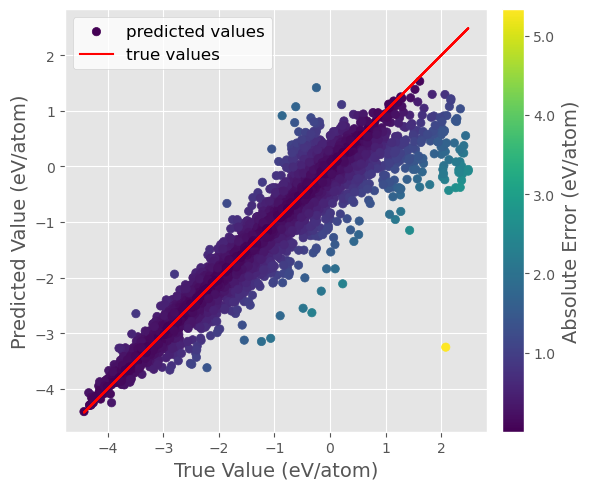

Training scores:
MAE = 0.1404
MSE = 0.0717
RMSE = 0.2678
r^2 = 0.9469


In [4]:
plot_prediction(X_test, y_test, com, name='Formation Energy', model_name='Committee', save='models/matbench/com_eform_matbench_plot.png', format='png')

# AL Query Strategies

## Training

In [7]:
def al_loop_rnd(
    model,
    n_initial=7106,
    batch_size=5000,
    n_cycles=None,
    random_state=42,
    n_runs=1,
    save=None,
):
    '''
    Run a Random sampling active learning loop over a regression task.

    Args:
        model: Base estimator to train and wrap in a BaggingRegressor committee (sklearn-compatible regressor).
        n_initial: Number of randomly selected initial samples (int).
        batch_size: Number of samples to query and label per cycle (int).
        n_cycles: Number of AL cycles to run, if None runs until the pool is exhausted (int or None).
        random_state: rng seed (int).
        n_runs: Number of independent runs with different initial labeled sets (int).
        save: File path to save the combined results, if None file is not saved (str or None).

    Returns:
        pd.DataFrame of all runs concatenated into a single flat DataFrame, with 'run' and 'cycle' columns for grouping.
    '''
    rng = np.random.default_rng(random_state)
    run_seeds = rng.integers(0, 2**31, size=n_runs)

    all_histories = []

    for run in range(n_runs):
        run_seed = run_seeds[run]
        run_rng = np.random.default_rng(run_seed)

        print(f'\n{'='*60}')
        print(f'Run {run + 1}/{n_runs}  (seed={run_seed})')
        print(f'{'='*60}')
        
        # ── Label pool ─────────────────────────────────────────────────────────────────
        y_pool = np.full(len(X_train), MISSING_LABEL)
        initial_idx = rng.choice(len(X_train), size=n_initial, replace=False)
        y_pool[initial_idx] = y_train[initial_idx]
        
        # ── Query strategy ─────────────────────────────────────────────────────────────
        rnd = RandomSampling(random_state=random_state)
        
        # ── History ────────────────────────────────────────────────────────────────────
        history = {
            'run': [],
            'cycle': [],
            'n_labeled': [],
            'mae_test': [],
            'mse_test': [],
            'rmse_test': [],
            'r2_test': [],
            'mae_val': [],
            'mse_val': [],
            'rmse_val': [],
            'r2_val': [],
            'queried_idx': [],
        }
        
        reg = clone(model)
    
        if n_cycles is None:
            n_cycles = math.ceil((len(X_train)-n_initial)/batch_size) + 1
        
        # ── Active-learning loop ───────────────────────────────────────────────────────
        for cycle in range(n_cycles):
            labeled_idx = labeled_indices(y_pool)
            unlabeled_idx = unlabeled_indices(y_pool)
            n_labeled = len(labeled_indices(y_pool))           
        
            # 1. Train model
            reg.fit(X_train[labeled_idx], y_pool[labeled_idx])
        
            # 2. Record
            y_pred_test = reg.predict(X_test)
            y_pred_val = reg.predict(X_val)
            
            mae_test = mean_absolute_error(y_test, y_pred_test)
            mse_test = mean_squared_error(y_test, y_pred_test)
            rmse_test = root_mean_squared_error(y_test, y_pred_test)
            r2_test = r2_score(y_test, y_pred_test)
        
            mae_val = mean_absolute_error(y_val, y_pred_val)
            mse_val = mean_squared_error(y_val, y_pred_val)
            rmse_val = root_mean_squared_error(y_val, y_pred_val)
            r2_val = r2_score(y_val, y_pred_val)

            history['run'].append(run+1)
            history['cycle'].append(cycle+1)
            history['n_labeled'].append(n_labeled)
            history['mae_test'].append(mae_test)
            history['mse_test'].append(mse_test)
            history['rmse_test'].append(rmse_test)
            history['r2_test'].append(r2_test)
            history['mae_val'].append(mae_val)
            history['mse_val'].append(mse_val)
            history['rmse_val'].append(rmse_val)
            history['r2_val'].append(r2_val)

            if cycle == 0:
                history['queried_idx'].append(initial_idx.tolist())
            else:
                history['queried_idx'].append(query_idx.tolist())
                
            if len(unlabeled_idx) == 0:    
                print(
                    f'Cycle {cycle + 1:>2} | '
                    f'Labeled: {n_labeled:>5}/{len(X_train)} | '
                    f'MAE: {mae_test:.4f} Eh | '
                    f'RMSE: {rmse_test:.4f} Eh | '
                    f'R2: {r2_test:.4f} | '
                )
                print('All pool samples labeled.')
                break
                
            # 3. Query random samples
            query_idx = rnd.query(X=X_train, y=y_pool, batch_size=batch_size)
            
            y_pool[query_idx] = y_train[query_idx]
                
            print(
                f'Cycle {cycle + 1:>2} | '
                f'Labeled: {n_labeled:>5}/{len(X_train)} | '
                f'MAE: {mae_test:.4f} Eh | '
                f'RMSE: {rmse_test:.4f} Eh | '
                f'R2: {r2_test:.4f} | '
            )            
            
        print(f'\nDone. Final labeled count: {labeled_indices(y_pool).size}/{len(X_train)}')
        
        all_histories.append(history)

    df = pd.concat([pd.DataFrame(h) for h in all_histories], ignore_index=True)
    if save is not None:
        df.to_csv(save, index=False)
    
    return df

In [8]:
def al_loop_qbc(
    model,
    n_initial=7106,
    batch_size=5000,
    n_cycles=None,
    random_state=42,
    n_runs=1,
    save=None,
):
    '''
    Run a Uncertainty sampling (Query-by-Committee with heterogeneous models) active learning loop over a regression task.

    Args:
        models: Committee models of several base estimators (sklearn VotingRegressor).
        n_initial: Number of randomly selected initial samples (int).
        batch_size: Number of samples to query and label per cycle (int).
        n_cycles: Number of AL cycles to run, if None runs until the pool is exhausted (int or None).
        random_state: rng seed (int).
        n_runs: Number of independent runs with different initial labeled sets (int).
        save: File path to save the combined results, if None file is not saved (str or None).

    Returns:
        pd.DataFrame of all runs concatenated into a single flat DataFrame, with 'run' and 'cycle' columns for grouping.
    '''
    rng = np.random.default_rng(random_state)
    run_seeds = rng.integers(0, 2**31, size=n_runs)

    all_histories = []

    for run in range(n_runs):
        run_seed = run_seeds[run]
        run_rng = np.random.default_rng(run_seed)

        print(f'\n{'='*60}')
        print(f'Run {run + 1}/{n_runs}  (seed={run_seed})')
        print(f'{'='*60}')
        
        # ── Label pool ─────────────────────────────────────────────────────────────────
        y_pool = np.full(len(X_train), MISSING_LABEL)
        initial_idx = rng.choice(len(X_train), size=n_initial, replace=False)
        y_pool[initial_idx] = y_train[initial_idx]
        
        # ── Query strategy ─────────────────────────────────────────────────────────────
        qbc = QueryByCommittee(random_state=random_state)
        
        # ── History ────────────────────────────────────────────────────────────────────
        history = {
            'run': [],
            'cycle': [],
            'n_labeled': [],
            'mae_test': [],
            'mse_test': [],
            'rmse_test': [],
            'r2_test': [],
            'mae_val': [],
            'mse_val': [],
            'rmse_val': [],
            'r2_val': [],
            'mean_uncertainty': [],   # avg utility score of queried batch
            'max_uncertainty': [],   # highest utility in the queried batch
            'queried_idx': [],
        }
        
        reg = clone(model)
    
        if n_cycles is None:
            n_cycles = math.ceil((len(X_train)-n_initial)/batch_size) + 1
        
        # ── Active-learning loop ───────────────────────────────────────────────────────
        for cycle in range(n_cycles):
            labeled_idx = labeled_indices(y_pool)
            unlabeled_idx = unlabeled_indices(y_pool)
            n_labeled = len(labeled_indices(y_pool))           
        
            reg.fit(X_train[labeled_idx], y_pool[labeled_idx])
            
            # 1. Train committee
            ensemble = SklearnRegressor(
                estimator=reg, random_state=random_state
            )
        
            # 2. Record
            y_pred_test = reg.predict(X_test)
            y_pred_val = reg.predict(X_val)
            
            mae_test = mean_absolute_error(y_test, y_pred_test)
            mse_test = mean_squared_error(y_test, y_pred_test)
            rmse_test = root_mean_squared_error(y_test, y_pred_test)
            r2_test = r2_score(y_test, y_pred_test)
        
            mae_val = mean_absolute_error(y_val, y_pred_val)
            mse_val = mean_squared_error(y_val, y_pred_val)
            rmse_val = root_mean_squared_error(y_val, y_pred_val)
            r2_val = r2_score(y_val, y_pred_val)

            history['run'].append(run+1)
            history['cycle'].append(cycle+1)
            history['n_labeled'].append(n_labeled)
            history['mae_test'].append(mae_test)
            history['mse_test'].append(mse_test)
            history['rmse_test'].append(rmse_test)
            history['r2_test'].append(r2_test)
            history['mae_val'].append(mae_val)
            history['mse_val'].append(mse_val)
            history['rmse_val'].append(rmse_val)
            history['r2_val'].append(r2_val)

            if cycle == 0:
                history['queried_idx'].append(initial_idx.tolist())
            else:
                history['queried_idx'].append(query_idx.tolist())
            
            if len(unlabeled_idx) == 0:
                history['mean_uncertainty'].append(0.0)
                history['max_uncertainty'].append(0.0)
                    
                print(
                    f'Cycle {cycle + 1:>2} | '
                    f'Labeled: {n_labeled:>5}/{len(X_train)} | '
                    f'MAE: {mae_test:.4f} Eh | '
                    f'RMSE: {rmse_test:.4f} Eh | '
                    f'R2: {r2_test:.4f} | '
                    f'Uncertainty — mean: {0:.4f} Eh  '
                    f'max: {0:.4f} Eh'
                )
                print('All pool samples labeled.')
                break
                
            # 3. Query most uncertain samples
            query_idx, utilities = call_func(
                qbc.query,
                X=X_train,
                y=y_pool,
                reg=reg,
                ensemble=ensemble,
                fit_ensemble=True,
                batch_size=batch_size,
                return_utilities=True,
            )
            
            y_pool[query_idx] = y_train[query_idx]            
            
            queried_utilities = utilities[0, query_idx]  # shape (1, n_pool)        
            
            history['mean_uncertainty'].append(queried_utilities.mean())
            history['max_uncertainty'].append(queried_utilities.max())
                
            print(
                f'Cycle {cycle + 1:>2} | '
                f'Labeled: {n_labeled:>5}/{len(X_train)} | '
                f'MAE: {mae_test:.4f} Eh | '
                f'RMSE: {rmse_test:.4f} Eh | '
                f'R2: {r2_test:.4f} | '
                f'Uncertainty — mean: {np.sqrt(queried_utilities.mean()):.4f} Eh  '
                f'max: {np.sqrt(queried_utilities.max()):.4f} Eh'
            )

            
            
        print(f'\nDone. Final labeled count: {labeled_indices(y_pool).size}/{len(X_train)}')
        
        all_histories.append(history)

    df = pd.concat([pd.DataFrame(h) for h in all_histories], ignore_index=True)
    if save is not None:
        df.to_csv(save, index=False)
        
    del reg
    del all_histories
    del history
    
    return df

In [11]:
def al_loop_div(
    model,
    n_initial=7106,
    batch_size=5000,
    n_cycles=None,
    random_state=42,
    n_runs=1,
    save=None,
):
    '''
    Run a Diversity sampling (Tanimoto distance) active learning loop over a regression task.

    Args:
        model: Base estimator to train and wrap in a BaggingRegressor committee (sklearn-compatible regressor).
        n_initial: Number of randomly selected initial samples (int).
        batch_size: Number of samples to query and label per cycle (int).
        n_cycles: Number of AL cycles to run, if None runs until the pool is exhausted (int or None).
        random_state: rng seed (int).
        n_runs: Number of independent runs with different initial labeled sets (int).
        save: File path to save the combined results, if None file is not saved (str or None).

    Returns:
        pd.DataFrame of all runs concatenated into a single flat DataFrame, with 'run' and 'cycle' columns for grouping.
    '''
    rng = np.random.default_rng(random_state)
    run_seeds = rng.integers(0, 2**31, size=n_runs)

    all_histories = []
    
    for run in range(n_runs):
        run_seed = run_seeds[run]
        run_rng = np.random.default_rng(run_seed)

        print(f'\n{'='*60}')
        print(f'Run {run + 1}/{n_runs}  (seed={run_seed})')
        print(f'{'='*60}')
        
        # ── Label pool ─────────────────────────────────────────────────────────────────
        y_pool = np.full(len(X_train), MISSING_LABEL)
        initial_idx = rng.choice(len(X_train), size=n_initial, replace=False)
        y_pool[initial_idx] = y_train[initial_idx]

        # ── Query strategy ─────────────────────────────────────────────────────────────
        qs = TypiClust(missing_label=MISSING_LABEL, random_state=random_state)
        
        # ── History ────────────────────────────────────────────────────────────────────
        history = {
            'run': [],
            'cycle': [],
            'n_labeled': [],
            'mae_test': [],
            'mse_test': [],
            'rmse_test': [],
            'r2_test': [],
            'mae_val': [],
            'mse_val': [],
            'rmse_val': [],
            'r2_val': [],
            'queried_idx': [],
        }
        
        reg = clone(model)
    
        if n_cycles is None:
            n_cycles = math.ceil((len(X_train)-n_initial)/batch_size) + 1
        
        # ── Active-learning loop ───────────────────────────────────────────────────────
        for cycle in range(n_cycles):
            labeled_idx = labeled_indices(y_pool)
            unlabeled_idx = unlabeled_indices(y_pool)
            n_labeled = len(labeled_indices(y_pool))           
        
            # 1. Train model
            reg.fit(X_train[labeled_idx], y_pool[labeled_idx])
        
            # 2. Record
            y_pred_test = reg.predict(X_test)
            y_pred_val = reg.predict(X_val)
            
            mae_test = mean_absolute_error(y_test, y_pred_test)
            mse_test = mean_squared_error(y_test, y_pred_test)
            rmse_test = root_mean_squared_error(y_test, y_pred_test)
            r2_test = r2_score(y_test, y_pred_test)
        
            mae_val = mean_absolute_error(y_val, y_pred_val)
            mse_val = mean_squared_error(y_val, y_pred_val)
            rmse_val = root_mean_squared_error(y_val, y_pred_val)
            r2_val = r2_score(y_val, y_pred_val)

            history['run'].append(run+1)
            history['cycle'].append(cycle+1)
            history['n_labeled'].append(n_labeled)
            history['mae_test'].append(mae_test)
            history['mse_test'].append(mse_test)
            history['rmse_test'].append(rmse_test)
            history['r2_test'].append(r2_test)
            history['mae_val'].append(mae_val)
            history['mse_val'].append(mse_val)
            history['rmse_val'].append(rmse_val)
            history['r2_val'].append(r2_val)

            if cycle == 0:
                history['queried_idx'].append(initial_idx.tolist())
            else:
                history['queried_idx'].append(query_idx.tolist())
            
            if len(unlabeled_idx) == 0:                    
                print(
                    f'Cycle {cycle + 1:>2} | '
                    f'Labeled: {n_labeled:>5}/{len(X_train)} | '
                    f'MAE: {mae_test:.4f} Eh | '
                    f'RMSE: {rmse_test:.4f} Eh | '
                    f'R2: {r2_test:.4f} | '
                )
                print('All pool samples labeled.')
                break
                
            # 3. Query random samples            
            query_idx = qs.query(
                X=X_train,
                y=y_pool,
                candidates=unlabeled_idx,
                batch_size=batch_size,
            )
            
            y_pool[query_idx] = y_train[query_idx]

            print(
                f'Cycle {cycle + 1:>2} | '
                f'Labeled: {n_labeled:>5}/{len(X_train)} | '
                f'MAE: {mae_test:.4f} Eh | '
                f'RMSE: {rmse_test:.4f} Eh | '
                f'R2: {r2_test:.4f} | '
            )            
            
        print(f'\nDone. Final labeled count: {labeled_indices(y_pool).size}/{len(X_train)}')
        
        all_histories.append(history)

    df = pd.concat([pd.DataFrame(h) for h in all_histories], ignore_index=True)
    if save is not None:
        df.to_csv(save, index=False)

    del reg
    del all_histories
    del history
    
    return df

In [9]:
al_loop_rnd(com, n_runs=5, n_initial=5000, batch_size=5000, n_cycles=10, save='../al/com/matbench/al_history_com_rnd_eform_matbench.csv')


Run 1/5  (seed=191664964)
Cycle  1 | Labeled:  5000/106201 | MAE: 0.1831 Eh | RMSE: 0.3197 Eh | R2: 0.9243 | 
Cycle  2 | Labeled: 10000/106201 | MAE: 0.1715 Eh | RMSE: 0.3080 Eh | R2: 0.9298 | 
Cycle  3 | Labeled: 15000/106201 | MAE: 0.1647 Eh | RMSE: 0.2968 Eh | R2: 0.9348 | 
Cycle  4 | Labeled: 20000/106201 | MAE: 0.1607 Eh | RMSE: 0.2916 Eh | R2: 0.9371 | 
Cycle  5 | Labeled: 25000/106201 | MAE: 0.1573 Eh | RMSE: 0.2859 Eh | R2: 0.9395 | 
Cycle  6 | Labeled: 30000/106201 | MAE: 0.1549 Eh | RMSE: 0.2833 Eh | R2: 0.9406 | 
Cycle  7 | Labeled: 35000/106201 | MAE: 0.1528 Eh | RMSE: 0.2812 Eh | R2: 0.9414 | 
Cycle  8 | Labeled: 40000/106201 | MAE: 0.1511 Eh | RMSE: 0.2802 Eh | R2: 0.9419 | 
Cycle  9 | Labeled: 45000/106201 | MAE: 0.1493 Eh | RMSE: 0.2793 Eh | R2: 0.9422 | 
Cycle 10 | Labeled: 50000/106201 | MAE: 0.1479 Eh | RMSE: 0.2770 Eh | R2: 0.9432 | 

Done. Final labeled count: 55000/106201

Run 2/5  (seed=1662057958)
Cycle  1 | Labeled:  5000/106201 | MAE: 0.1845 Eh | RMSE: 0.3227

,run,cycle,n_labeled,mae_test,mse_test,rmse_test,r2_test,mae_val,mse_val,rmse_val,r2_val,queried_idx
0,1,1,5000,0.183146,0.102194,0.319677,0.924343,0.180333,0.098638,0.314067,0.927480,"[78190, 69123, 63486, 3428, 20025, 50461, 6867..."
1,1,2,10000,0.171478,0.094853,0.307982,0.929777,0.169177,0.091422,0.302360,0.932786,"[43249, 63527, 21565, 46790, 71115, 20190, 628..."
2,1,3,15000,0.164718,0.088076,0.296776,0.934795,0.162262,0.084749,0.291117,0.937691,"[45632, 94194, 88202, 8431, 18347, 9675, 88274..."
3,1,4,20000,0.160737,0.085029,0.291597,0.937051,0.160104,0.083036,0.288159,0.938951,"[20527, 49489, 65462, 14432, 58982, 15152, 306..."
4,1,5,25000,0.157281,0.081758,0.285934,0.939472,0.157092,0.080089,0.283000,0.941117,"[4149, 33034, 4667, 11545, 72115, 101445, 7828..."
5,1,6,30000,0.154862,0.080234,0.283255,0.940601,0.154466,0.078925,0.280936,0.941973,"[86916, 74690, 67245, 48832, 89876, 55307, 572..."
6,1,7,35000,0.152791,0.079100,0.281247,0.941440,0.152940,0.078269,0.279766,0.942456,"[74272, 67029, 84448, 38343, 75103, 50744, 339..."
7,1,8,40000,0.151149,0.078504,0.280186,0.941881,0.150537,0.076770,0.277075,0.943557,"[92874, 30590, 97347, 32313, 22709, 61542, 984..."
8,1,9,45000,0.149330,0.078034,0.279346,0.942229,0.148794,0.075838,0.275387,0.944243,"[84570, 55166, 79716, 16776, 11404, 64746, 536..."
9,1,10,50000,0.147920,0.076723,0.276990,0.943199,0.147969,0.075404,0.274597,0.944562,"[7209, 52379, 50126, 29249, 65506, 54516, 9499..."


In [10]:
al_loop_qbc(com, n_runs=5, n_initial=5000, batch_size=5000, n_cycles=10, save='../al/com/matbench/al_history_com_unc_eform_matbench.csv')


Run 1/5  (seed=191664964)
Cycle  1 | Labeled:  5000/106201 | MAE: 0.1831 Eh | RMSE: 0.3197 Eh | R2: 0.9243 | Uncertainty — mean: 0.5143 Eh  max: 0.8948 Eh
Cycle  2 | Labeled: 10000/106201 | MAE: 0.1853 Eh | RMSE: 0.3067 Eh | R2: 0.9304 | Uncertainty — mean: 0.4819 Eh  max: 0.8182 Eh
Cycle  3 | Labeled: 15000/106201 | MAE: 0.1779 Eh | RMSE: 0.2944 Eh | R2: 0.9358 | Uncertainty — mean: 0.4463 Eh  max: 0.8400 Eh
Cycle  4 | Labeled: 20000/106201 | MAE: 0.1708 Eh | RMSE: 0.2877 Eh | R2: 0.9387 | Uncertainty — mean: 0.4269 Eh  max: 0.6469 Eh
Cycle  5 | Labeled: 25000/106201 | MAE: 0.1666 Eh | RMSE: 0.2830 Eh | R2: 0.9407 | Uncertainty — mean: 0.4101 Eh  max: 0.7492 Eh
Cycle  6 | Labeled: 30000/106201 | MAE: 0.1625 Eh | RMSE: 0.2798 Eh | R2: 0.9420 | Uncertainty — mean: 0.4011 Eh  max: 0.6551 Eh
Cycle  7 | Labeled: 35000/106201 | MAE: 0.1606 Eh | RMSE: 0.2779 Eh | R2: 0.9428 | Uncertainty — mean: 0.3876 Eh  max: 0.6390 Eh
Cycle  8 | Labeled: 40000/106201 | MAE: 0.1576 Eh | RMSE: 0.2759 Eh | 

,run,cycle,n_labeled,mae_test,mse_test,rmse_test,r2_test,mae_val,mse_val,rmse_val,r2_val,mean_uncertainty,max_uncertainty,queried_idx
0,1,1,5000,0.183146,0.102194,0.319677,0.924343,0.180333,0.098638,0.314067,0.927480,0.264526,0.800589,"[78190, 69123, 63486, 3428, 20025, 50461, 6867..."
1,1,2,10000,0.185258,0.094071,0.306710,0.930356,0.181415,0.089524,0.299205,0.934181,0.232202,0.669453,"[68658, 5317, 39966, 60626, 32028, 91423, 7498..."
2,1,3,15000,0.177872,0.086659,0.294380,0.935843,0.176181,0.082795,0.287741,0.939128,0.199176,0.705634,"[25045, 8778, 100120, 38684, 38338, 34068, 105..."
3,1,4,20000,0.170763,0.082777,0.287710,0.938718,0.169434,0.078468,0.280121,0.942309,0.182204,0.418464,"[65322, 54627, 29606, 7114, 16101, 14378, 9422..."
4,1,5,25000,0.166634,0.080108,0.283034,0.940693,0.165222,0.076177,0.276001,0.943994,0.168178,0.561340,"[77610, 70635, 14264, 72869, 105628, 42817, 82..."
5,1,6,30000,0.162458,0.078280,0.279786,0.942047,0.160968,0.074591,0.273113,0.945160,0.160899,0.429181,"[92991, 84129, 85810, 16834, 21200, 319, 47061..."
6,1,7,35000,0.160616,0.077205,0.277858,0.942843,0.159368,0.073614,0.271319,0.945878,0.150238,0.408277,"[75308, 104168, 86994, 30472, 67288, 99648, 49..."
7,1,8,40000,0.157583,0.076101,0.275864,0.943660,0.156703,0.072435,0.269138,0.946745,0.138995,0.293708,"[21385, 59180, 40898, 99415, 10763, 9848, 7586..."
8,1,9,45000,0.154531,0.075122,0.274083,0.944385,0.153421,0.071828,0.268008,0.947191,0.137644,0.414634,"[52544, 85200, 27817, 8453, 70839, 81452, 6524..."
9,1,10,50000,0.150809,0.073131,0.270428,0.945859,0.150010,0.069853,0.264297,0.948643,0.127574,0.294270,"[15876, 72748, 87395, 80609, 30941, 75685, 242..."


In [9]:
al_loop_div(com, n_runs=5, n_initial=5000, batch_size=5000, n_cycles=10, save='../al/com/matbench/al_history_com_div_eform_matbench.csv')


Run 1/5  (seed=191664964)
Cycle  1 | Labeled:  5000/106201 | MAE: 0.1831 Eh | RMSE: 0.3197 Eh | R2: 0.9243 | 
Cycle  2 | Labeled: 10000/106201 | MAE: 0.1680 Eh | RMSE: 0.3040 Eh | R2: 0.9316 | 
Cycle  3 | Labeled: 15000/106201 | MAE: 0.1638 Eh | RMSE: 0.2968 Eh | R2: 0.9348 | 
Cycle  4 | Labeled: 20000/106201 | MAE: 0.1611 Eh | RMSE: 0.2904 Eh | R2: 0.9375 | 
Cycle  5 | Labeled: 25000/106201 | MAE: 0.1580 Eh | RMSE: 0.2856 Eh | R2: 0.9396 | 
Cycle  6 | Labeled: 30000/106201 | MAE: 0.1567 Eh | RMSE: 0.2820 Eh | R2: 0.9411 | 
Cycle  7 | Labeled: 35000/106201 | MAE: 0.1547 Eh | RMSE: 0.2796 Eh | R2: 0.9421 | 
Cycle  8 | Labeled: 40000/106201 | MAE: 0.1534 Eh | RMSE: 0.2794 Eh | R2: 0.9422 | 
Cycle  9 | Labeled: 45000/106201 | MAE: 0.1523 Eh | RMSE: 0.2763 Eh | R2: 0.9435 | 
Cycle 10 | Labeled: 50000/106201 | MAE: 0.1501 Eh | RMSE: 0.2746 Eh | R2: 0.9442 | 

Done. Final labeled count: 55000/106201

Run 2/5  (seed=1662057958)
Cycle  1 | Labeled:  5000/106201 | MAE: 0.1845 Eh | RMSE: 0.3227

ValueError: All arrays must be of the same length

In [2]:
def df_groupby(df):
    '''
    Regroups the AL history df into a new df for plotting.

    Args:
        df : AL history df (pd.DataFrame)
    '''
    df = df.groupby('n_labeled').agg(
        mae_test=('mae_test', 'mean'),   min_mae_test=('mae_test', 'min'),   max_mae_test=('mae_test', 'max'),
        mse_test=('mse_test', 'mean'),   min_mse_test=('mse_test', 'min'),   max_mse_test=('mse_test', 'max'),
        rmse_test=('rmse_test', 'mean'), min_rmse_test=('rmse_test', 'min'), max_rmse_test=('rmse_test', 'max'),
        r2_test=('r2_test', 'mean'),     min_r2_test=('r2_test', 'min'),     max_r2_test=('r2_test', 'max'),
        mae_val=('mae_val', 'mean'),   min_mae_val=('mae_val', 'min'),   max_mae_val=('mae_val', 'max'),
        mse_val=('mse_val', 'mean'),   min_mse_val=('mse_val', 'min'),   max_mse_val=('mse_val', 'max'),
        rmse_val=('rmse_val', 'mean'), min_rmse_val=('rmse_val', 'min'), max_rmse_val=('rmse_val', 'max'),
        r2_val=('r2_val', 'mean'),     min_r2_val=('r2_val', 'min'),     max_r2_val=('r2_val', 'max'),
    ).reset_index()
    return df

In [6]:
import matplotlib.ticker as ticker

def plot_al(dfs, labels, score=None, metric='rmse', save=None, format='pdf'):
    '''
    Plot AL metrics base on labeled samples.

    Args:
        dfs : List of Data Frames modified with df_groupby (list).
        labels : List of AL strategies (list).
        score : Dictionary of metric scores of baseline model (dict).
        save : Save path (str).
        format : Save format (str).
    '''
    if metric == 'rmse':
        metrics = [('rmse_test', 'RMSE on Formation Energy (eV/atom)')]
    if metric == 'r2':
        metrics = [('r2_test', 'R²')]
    if metric == 'mae':
        metrics = [('mae_test', 'MAE on Formation Energy (eV/atom)')]
    fig, ax = plt.subplots(figsize=(6, 6))

    # Generate a color palette dynamically based on the number of dataframes
    cmap = plt.get_cmap('tab10')
    colors = [cmap(i) for i in range(0, len(dfs))]
    # lines = ['-', '--', '-.', ':']

    for (key, label) in metrics:
        # Loop through dataframes, labels, and the auto-generated colors
        for df, name, color in zip(dfs, labels, colors):
            ax.plot(
                df['n_labeled'],
                df[key],
                color=color,
                # linestyle=line,
                label=name,
                linewidth=3,
            )
            ax.fill_between(
                df['n_labeled'],
                df[f'min_{key}'],
                df[f'max_{key}'],
                alpha=0.2,
                color=color,
            )
        if score is not None:
            baseline_val = score[key]
            ax.axhline(
                baseline_val,
                color='black',
                ls='-',
                linewidth=3,
                label=r'$\mathrm{RMSE}_{\mathrm{full}}$' f' = {baseline_val:.2f}' if key != 'r2_test' else r'$R^2_{\mathrm{full}}$' f' = {baseline_val:.3f}',
            )
            if key != 'r2_test':
                ax.axhline(
                baseline_val*1.1,
                color='gray',
                ls='--',
                linewidth=3,
                label=r'$1.1 \times \mathrm{RMSE}_{\mathrm{full}}$' f' = {1.1*baseline_val:.2f}',
            )
        
        ax.set_xscale('log')
        ax.xaxis.set_major_locator(ticker.LogLocator(base=10.0, subs=(0.5, 1.0, 2.0, 3.0, 5.0)))
        ax.xaxis.set_major_formatter(ticker.StrMethodFormatter("{x:,.0f}"))
        ax.xaxis.set_minor_locator(ticker.NullLocator())
        
        ymin, ymax = ax.get_ylim()
        ax.set_ylim(ymin - (ymax - ymin) * 0.05, ymax + (ymax - ymin) * 0.05)        
        ax.set_xlabel('Train size', fontsize=16)
        ax.set_ylabel(label, fontsize=16)
        ax.legend(facecolor='white', fontsize=14)
        ax.tick_params(axis='both', labelsize=14)

    plt.tight_layout()
    if save is not None:
        fig.savefig(save, format=format, dpi=300)
    plt.show()

In [18]:
import numpy as np

def find_target_samples(df, baseline_score, multiplier=1.1):
    """
    Calculates the exact number of labeled samples required to reach a target score 
    (multiplier * baseline) using log-linear interpolation.

    Args:
        df (pd.DataFrame): DataFrame containing the active learning curve data.
        metric_key (str): The column name of the metric (e.g., 'rmse_test').
        baseline_score (float): The baseline score (RMSE_full).
        multiplier (float): The multiplier for the baseline score (default 1.1).
        x_col (str): The column name for the sample sizes (default 'n_labeled').

    Returns:
        float: The interpolated number of samples, or None if the curve never crosses the target.
    """
    target = baseline_score * multiplier
    
    x = df['n_labeled'].values
    y = df['rmse_test'].values
    
    for i in range(len(x) - 1):
        x0, x1 = x[i], x[i+1]
        y0, y1 = y[i], y[i+1]
        
        # Check if the curve crosses the target threshold between these two points
        if (y0 >= target and y1 <= target) or (y0 <= target and y1 >= target):
            
            # If the points are identical on the y-axis, return the first x
            if y0 == y1:
                return x0
                
            # Interpolate X in log-space
            log_x0, log_x1 = np.log10(x0), np.log10(x1)
            log_x_int = log_x0 + (log_x1 - log_x0) * (target - y0) / (y1 - y0)
            
            return 10 ** log_x_int
            
    return None # Target was never reached

In [3]:
rnd = df_groupby(pd.read_csv('active_learning/com/matbench/al_history_com_rnd_eform_matbench.csv'))
div = df_groupby(pd.read_csv('active_learning/com/matbench/al_history_com_div_eform_matbench.csv'))
unc = df_groupby(pd.read_csv('active_learning/com/matbench/al_history_com_qbc_eform_matbench.csv'))

In [4]:
rnd[['n_labeled','rmse_test']]

,n_labeled,rmse_test
0,5000,0.322046
1,10000,0.304350
2,15000,0.295870
3,20000,0.290721
4,25000,0.286293
5,30000,0.283232
6,35000,0.281095
7,40000,0.279231
8,45000,0.278170
9,50000,0.276056


In [5]:
div[['n_labeled','rmse_test']]

,n_labeled,rmse_test
0,5000,0.322046
1,10000,0.304710
2,15000,0.296819
3,20000,0.290625
4,25000,0.285420
5,30000,0.281556
6,35000,0.278779
7,40000,0.277686
8,45000,0.275436
9,50000,0.273318


In [6]:
unc[['n_labeled','rmse_test']]

,n_labeled,rmse_test
0,5000,0.322046
1,10000,0.302432
2,15000,0.292432
3,20000,0.287097
4,25000,0.282416
5,30000,0.279713
6,35000,0.276486
7,40000,0.274971
8,45000,0.272662
9,50000,0.270641


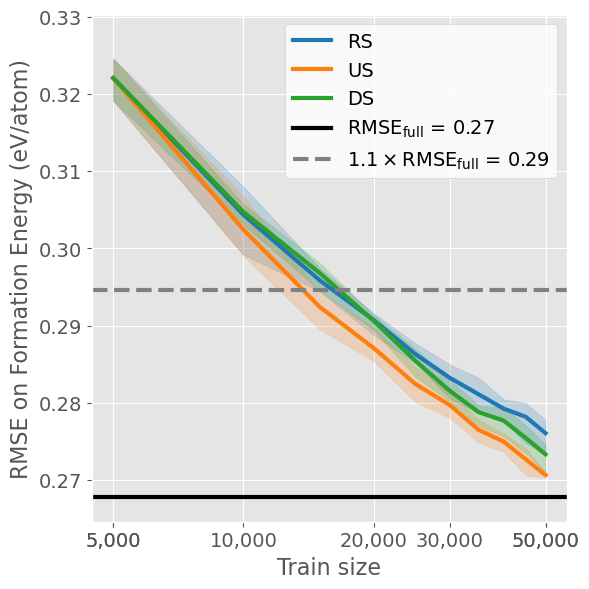

In [8]:
plot_al([rnd, unc, div], ['RS', 'US', 'DS'], score=com_score, metric='rmse', save='active_learning/com/matbench/al_rmse_eform_matbench.pdf', format='pdf')

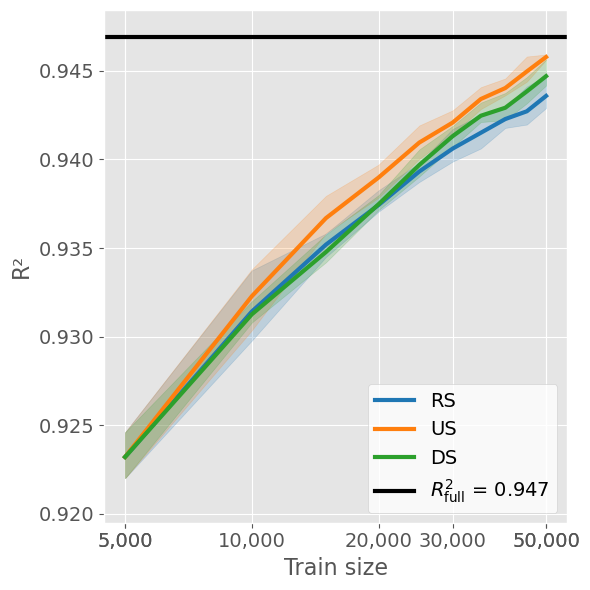

In [9]:
plot_al([rnd, unc, div], ['RS', 'US', 'DS'], score=com_score, metric='r2', save='active_learning/com/matbench/al_r2_eform_matbench.pdf', format='pdf')

In [5]:
committee = df_groupby(pd.read_csv('active_learning/com/matbench/al_history_com_qbc_eform_matbench.csv'))
schnet = df_groupby(pd.read_csv('../nn/active_learning/schnet/matbench/al_history_schnet_div_eform_matbench.csv'))

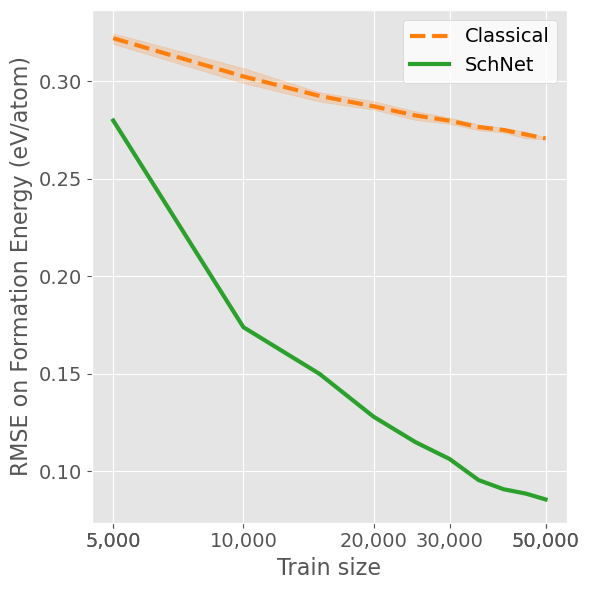

In [11]:
metric='rmse'
save='../al_matbench_rmse.pdf'
fig, ax = plt.subplots(figsize=(6, 6))

# Generate a color palette dynamically based on the number of dataframes
cmap = plt.get_cmap('tab10')
# lines = ['-', '--', '-.', ':']
if metric == 'rmse':
    metrics = [('rmse_test', 'RMSE on Formation Energy (eV/atom)')]
if metric == 'r2':
    metrics = [('r2_test', 'R²')]
if metric == 'mae':
    metrics = [('mae_test', 'MAE on HOMO-LUMO Gap (eV)')]

for (key, label) in metrics:
    # Loop through dataframes, labels, and the auto-generated colors
    ax.plot(
        committee['n_labeled'],
        committee[key],
        color=cmap(1),
        ls='--',
        label='Classical',
        linewidth=3,
    )
    ax.fill_between(
        committee['n_labeled'],
        committee[f'min_{key}'],
        committee[f'max_{key}'],
        alpha=0.2,
        color=cmap(1),
    )

    ax.plot(
        schnet['n_labeled'],
        schnet[key],
        color=cmap(2),
        ls='-',
        label='SchNet',
        linewidth=3,
    )
    
    ax.set_xscale('log')
    ax.xaxis.set_major_locator(ticker.LogLocator(base=10.0, subs=(0.5, 1.0, 2.0, 3.0, 5.0)))
    ax.xaxis.set_major_formatter(ticker.StrMethodFormatter("{x:,.0f}"))
    ax.xaxis.set_minor_locator(ticker.NullLocator())
    
    # ax.set_ylim(0.92, 0.95)
    ax.set_xlabel('Train size', fontsize=16)
    ax.set_ylabel(label, fontsize=16)
    ax.legend(facecolor='white', fontsize=14)
    ax.tick_params(axis='both', labelsize=14)

plt.tight_layout()
if save is not None:
    fig.savefig(save, format='pdf', dpi=300)
plt.show()

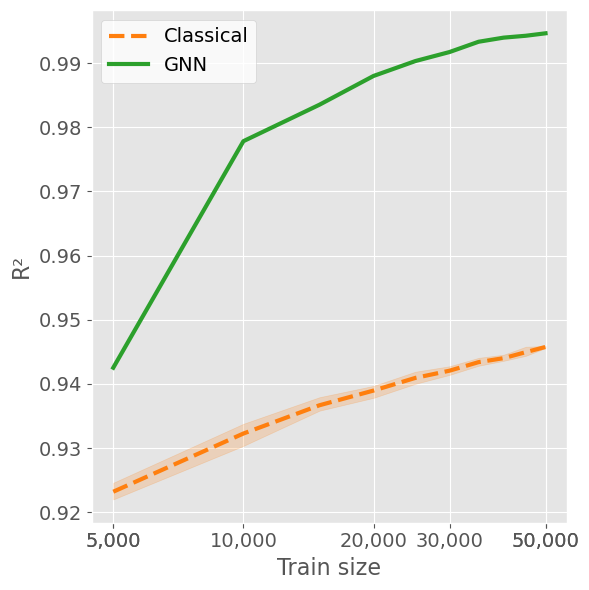

In [57]:
metric='r2'
save='../al_matbench_r2.png'
fig, ax = plt.subplots(figsize=(6, 6))

# Generate a color palette dynamically based on the number of dataframes
cmap = plt.get_cmap('tab10')
# lines = ['-', '--', '-.', ':']
if metric == 'rmse':
    metrics = [('rmse_test', 'RMSE on Formation Energy (eV/atom)')]
if metric == 'r2':
    metrics = [('r2_test', 'R²')]
if metric == 'mae':
    metrics = [('mae_test', 'MAE on HOMO-LUMO Gap (eV)')]

for (key, label) in metrics:
    # Loop through dataframes, labels, and the auto-generated colors
    ax.plot(
        committee['n_labeled'],
        committee[key],
        color=cmap(1),
        ls='--',
        label='Classical',
        linewidth=3,
    )
    ax.fill_between(
        committee['n_labeled'],
        committee[f'min_{key}'],
        committee[f'max_{key}'],
        alpha=0.2,
        color=cmap(1),
    )

    ax.plot(
        schnet['n_labeled'],
        schnet[key],
        color=cmap(2),
        ls='-',
        label='GNN',
        linewidth=3,
    )
    
    ax.set_xscale('log')
    ax.xaxis.set_major_locator(ticker.LogLocator(base=10.0, subs=(0.5, 1.0, 2.0, 3.0, 5.0)))
    ax.xaxis.set_major_formatter(ticker.StrMethodFormatter("{x:,.0f}"))
    ax.xaxis.set_minor_locator(ticker.NullLocator())
    
    # ax.set_ylim(0.92, 0.95)
    ax.set_xlabel('Train size', fontsize=16)
    ax.set_ylabel(label, fontsize=16)
    ax.legend(facecolor='white', fontsize=14)
    ax.tick_params(axis='both', labelsize=14)

plt.tight_layout()
if save is not None:
    fig.savefig(save, format='png', dpi=300)
plt.show()